# Mouse Plasma aggregation

Read the source protocol CSVs for one condition and write its compact, deduplicated union.

In [1]:
CONDITION="mouse_plasma"
WRITE_EXPORTS=True
NOTEBOOK_ID="aggregation_mouse_plasma"
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
here = Path.cwd().resolve()
ROOT = next(p for p in [here, *here.parents] if (p / "src/pep_compass").is_dir())
sys.path.insert(0, str(ROOT / "assets/tools/proteolysis_data_manager/src"))
from proteolysis_data_manager.protocols.half_life.filtering import load_half_life_data, prepare_protocol, export_protocol
from proteolysis_data_manager.integration.half_life.schema import CLEAN_COLUMNS, source_mask, row_key, typed
from proteolysis_data_manager.analysis.half_life.visualization import (formatted_table, duration_summary, plot_duration_distributions,
    plot_acceptance_conditions, plot_before_after, readable_time_axis, time_bins, DURATION_COLORS, DURATION_LABELS)
DATA_ROOT = ROOT / "data/half_time_datasets"
SERIES = ROOT / "assets/experiments/analysis/09_26/20_serum_proteolysis_calibration_max/notebooks/0_data_analysis_half_life"
RESULTS = SERIES.parents[1] / "results/0_data_analysis_half_life" / CONDITION / NOTEBOOK_ID
if WRITE_EXPORTS: RESULTS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi":110, "axes.spines.top":False, "axes.spines.right":False, "axes.grid":True, "grid.alpha":.12})
def table(frame):
    if len(frame)>30: display(HTML(f"<p>Preview: 30 of {len(frame)} rows.</p>"))
    display(HTML(formatted_table(frame, limit=30)))
def figure(fig, name):
    if WRITE_EXPORTS: fig.savefig(RESULTS / name, bbox_inches="tight")
    plt.show(); plt.close(fig)
def counts(frame):
    point=frame.half_life_seconds.notna()
    return {"observations":len(frame), "sequences":frame.sequence.nunique(), "numeric":int(point.sum()),
            "class_only":int((~point & frame.half_life_class.notna()).sum()),
            "unresolved":int((~point & frame.half_life_class.isna()).sum())}

from proteolysis_data_manager.integration.half_life.aggregation import aggregate_environment, source_accounting
SOURCES=["peplife2","plifepred","dramp","pepmsnd","cavaco"]


## Inputs and verified measurement identity

Central manifests verify input CSVs and their shared normalization/protocol policy. A shared source reference plus identical scientific fields establishes a repeated normalized measurement. Equal sequences or equal half-lives alone do not. Missing fields were already enriched during normalization, and the complete source/ID lists survive final aggregation.

No wide provenance columns or report files are added. Conflicting measurements remain separate; their explanations are in `normalized/remarks_<source>.md`.

In [2]:
if not WRITE_EXPORTS:
    raise RuntimeError("Template export disabled. Copy into a condition folder and enable WRITE_EXPORTS.")
before, after, lineage, possible, manifest = aggregate_environment(DATA_ROOT, CONDITION, SOURCES)
table(pd.DataFrame(manifest["inputs"]))
table(pd.DataFrame([{"condition":CONDITION,"source_input_rows":len(before),"final_measurements":len(after),"repeated_input_rows_merged":len(before)-len(after),**counts(after),"reported_ci95":int(after.ci_level.eq(.95).sum()),"unconfirmed_coincident_points":len(possible)}]))

source,csv,sha256,source_rows
peplife2,processed/mouse_plasma/sources/peplife2.csv,4cd29246efc7df71b7a8c9861b94abf95b087381e9750bc09f6827af93197be8,69
plifepred,processed/mouse_plasma/sources/plifepred.csv,04adf3ee2b9a116bcfe1cc336563a9273e09ca355ca52b63e4fa77d7a1481185,4
dramp,processed/mouse_plasma/sources/dramp.csv,b39517b0258e9a3f155c4ebf118e0596d59db411d7597c180568f80c0f645b11,0
pepmsnd,processed/mouse_plasma/sources/pepmsnd.csv,4ba47b36267922eca922aa80efa30a17ad30f08096697cdfd73bf7cc5de98c58,18
cavaco,processed/mouse_plasma/sources/cavaco.csv,b39517b0258e9a3f155c4ebf118e0596d59db411d7597c180568f80c0f645b11,0


condition,source_input_rows,final_measurements,repeated_input_rows_merged,observations,sequences,numeric,class_only,unresolved,reported_ci95,unconfirmed_coincident_points
mouse_plasma,91,88,3,88,65,69,10,9,0,6


## Source coverage, label availability and PEPlife2 overlap

Raw source representations and normalized measurements have different denominators: normalization merges verified repeated source rows. The next reduction selects species/matrix and the explicit assay mode, then applies pH/temperature gates. Tables account for each reduction.

Every retained row belongs to one label group: numerical, class-only, or unresolved. Missing half-life does not remove it. Shared sequences and verified shared measurements with PEPlife2 are reported separately; sequence overlap is not deduplication evidence.

coverage


source,raw_source_representations,normalized_measurements,condition_records,selected_assay_mode,other_known_mode,unknown_assay_mode,outside_ph_temperature,exported_source_records
peplife2,4500,4366,424,71,353,0,2,69
plifepred,424,261,10,5,5,0,1,4
dramp,111,111,0,0,0,0,0,0
pepmsnd,635,635,75,18,57,0,0,18
cavaco,16,16,0,0,0,0,0,0


label_types


source,exported_records,numeric,class_only,unresolved,without_numeric_half_life
peplife2,69,50,10,9,19
plifepred,4,4,0,0,0
dramp,0,0,0,0,0
pepmsnd,18,18,0,0,0
cavaco,0,0,0,0,0


peplife2_overlap


source,comparison,shared_sequences,shared_sequence_records,verified_same_measurements,new_sequences
peplife2,reference,52,69,None,0
plifepred,against PEPlife2,4,4,3,0
dramp,against PEPlife2,0,0,0,0
pepmsnd,against PEPlife2,3,3,0,13
cavaco,against PEPlife2,0,0,0,0


source,parameter,cavaco,dramp,peplife2,pepmsnd,plifepred
,ci_level,0,0,69,18,4
,ci_lower_seconds,0,0,69,18,4
,ci_upper_seconds,0,0,69,18,4
,half_life_class,0,0,9,0,0
,half_life_seconds,0,0,19,0,0
,matrix_fraction,0,0,69,18,4
,peptide_concentration_um,0,0,34,18,3
,ph,0,0,68,18,4
,replicate_count,0,0,69,18,4
,sd_seconds,0,0,69,18,4


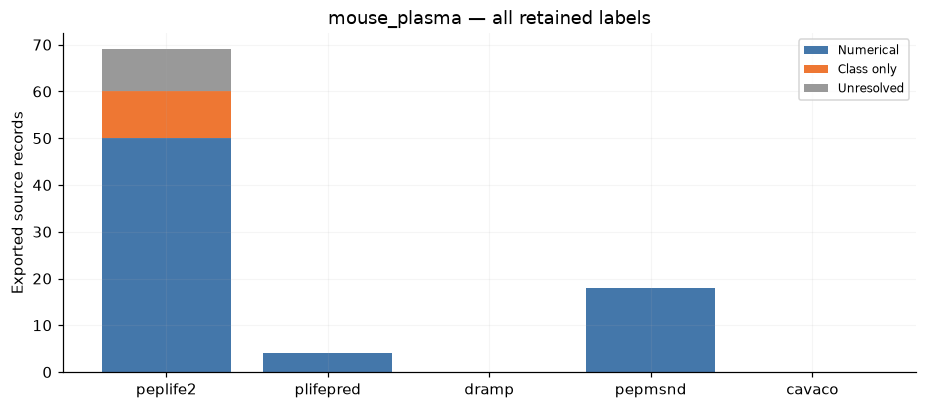

In [3]:
inventory=load_half_life_data(DATA_ROOT)
accounting=source_accounting(DATA_ROOT,inventory,before,after,manifest["configuration"],SOURCES)
for name in ["coverage","label_types","peplife2_overlap"]:
    print(name); table(accounting[name])
table(accounting["missingness"].pivot(index="parameter",columns="source",values="missing").reset_index())
labels=accounting["label_types"].set_index("source")
fig,ax=plt.subplots(figsize=(10,4)); bottom=pd.Series(0,index=labels.index)
for field,color,label in [("numeric","#4477AA","Numerical"),("class_only","#EE7733","Class only"),("unresolved","#999999","Unresolved")]:
    ax.bar(labels.index,labels[field],bottom=bottom,color=color,label=label);bottom+=labels[field]
ax.set(ylabel="Exported source records",title=CONDITION+" — all retained labels");ax.legend(fontsize=8)
figure(fig,"source_label_availability.png")
for _,r in accounting["label_types"].iterrows():
    assert r.numeric+r.class_only+r.unresolved==r.exported_records
for _,r in accounting["coverage"].iterrows():
    assert r.condition_records==r.selected_assay_mode+r.other_known_mode+r.unknown_assay_mode
    assert r.selected_assay_mode==r.outside_ph_temperature+r.exported_source_records

## Duration classes, distributions and missingness

**short** <30 min (blue); **medium** 30 min–6 h inclusive (orange); **long** >6 h (green); unresolved (gray). All numerical and class-only observations enter class counts. Numerical histograms use reported points or the explicitly documented CI-midpoint exception only.

Before/after counts here describe merging source copies of shared observations, not filtering out class-only data.

duration_class,time_interval,all_assigned_records,exact_point_records,bounded_or_non_numeric_records,stage
unresolved,no unique interval,9,0,9,Source CSV inputs
short,<30 min,19,19,0,Source CSV inputs
medium,30 min–6 h,34,33,1,Source CSV inputs
long,>6 h,29,20,9,Source CSV inputs
unresolved,no unique interval,9,0,9,Deduplicated union
short,<30 min,19,19,0,Deduplicated union
medium,30 min–6 h,31,30,1,Deduplicated union
long,>6 h,29,20,9,Deduplicated union


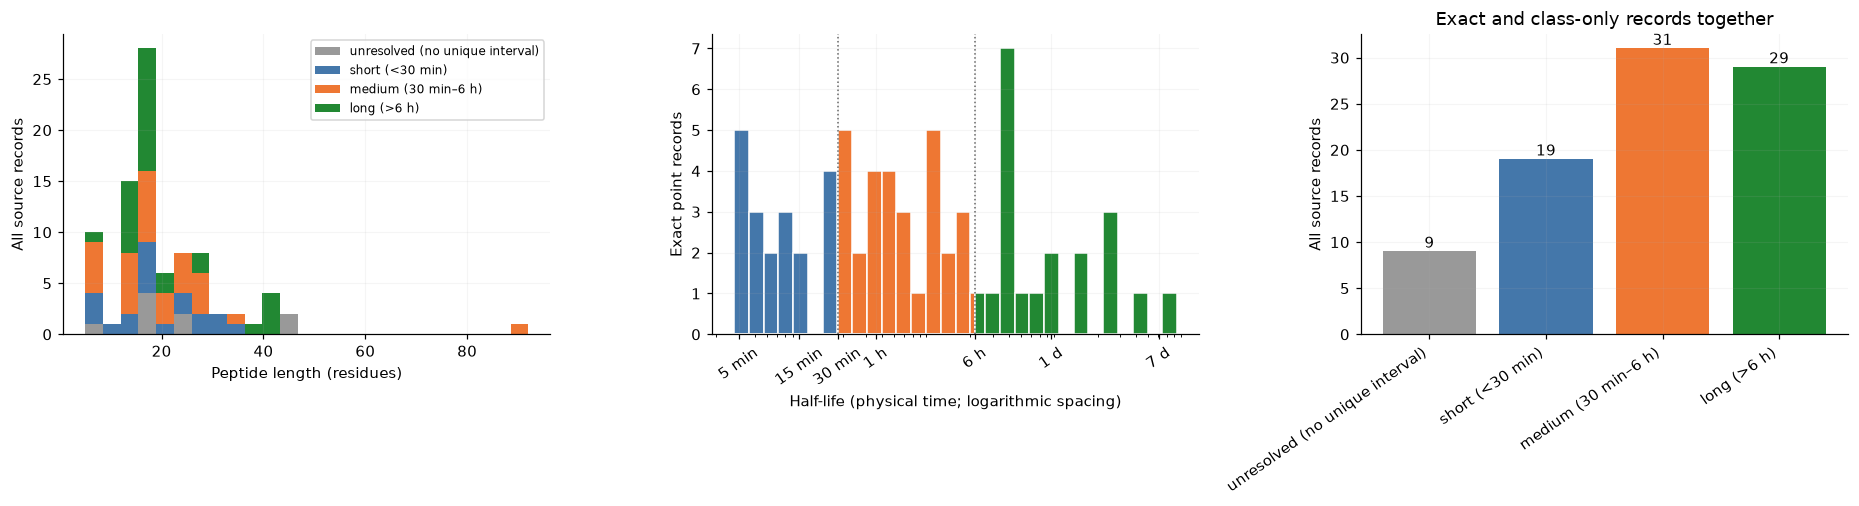

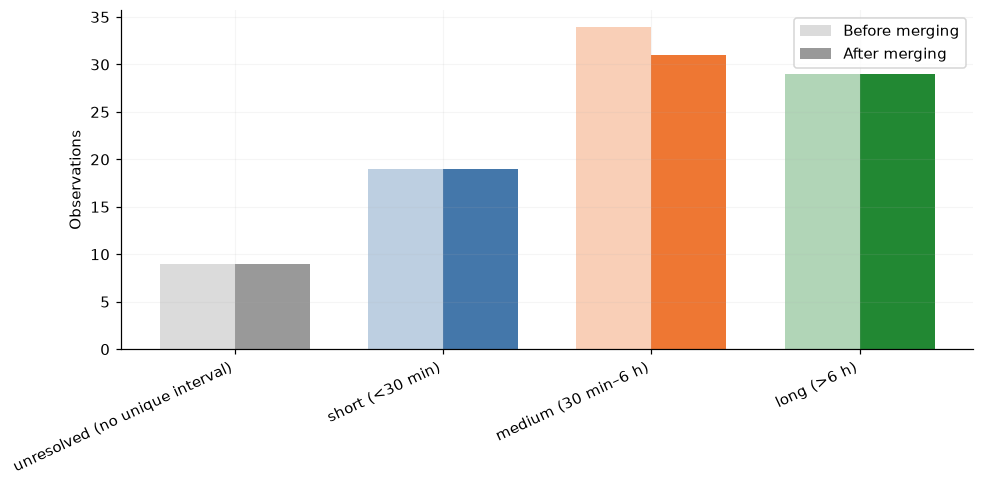

field,missing,denominator
sequence,0,88
sequence_length,0,88
chirality,18,88
topology,0,88
n_terminal_modification,0,88
c_terminal_modification,0,88
other_modifications,0,88
species,0,88
matrix,0,88
matrix_fraction,88,88


normalized_row_key,source,id
cc518959f41a30e732a0751514b10011b46ab14b76249f4d00dba96b7e9dcd6b,peplife2,all:1243
cc518959f41a30e732a0751514b10011b46ab14b76249f4d00dba96b7e9dcd6b,plifepred,mixed:1243
cc518959f41a30e732a0751514b10011b46ab14b76249f4d00dba96b7e9dcd6b,plifepred,natural:1243
650a386a13d9cccf4fee5c3f8b1278b681590368eae187ed07c4a0babaa42195,peplife2,all:1767
4d4486430fa5ee704c2684567bbfa27fd20ea407fe4f77c1aaeeae2d91a6e395,peplife2,all:1770
7fb1e39727be750c9d0f8c072c60e08129554db9dd3e39c7d6a19ae57bac02d4,peplife2,all:2068
c4da4db27d46b06a619556f50d219cf0c543fc6c25c58f5996528c41454bfb27,peplife2,all:2374
c4da4db27d46b06a619556f50d219cf0c543fc6c25c58f5996528c41454bfb27,plifepred,mixed:2374
5498ab50702b4a3fba635fff7c47f59334644cd5d9326147e658c56e1dabf436,peplife2,all:2375
243ac59224d9f65f0ff0241fdf7ad3cbf876b3a988ac7559b4376866678d6698,peplife2,all:2625


source,source_record_id,sequence,sequence_length,chirality,topology,n_terminal_modification,c_terminal_modification,other_modifications,species,matrix,matrix_fraction,temperature_c,ph,peptide_concentration_um,half_life_seconds,sd_seconds,ci_lower_seconds,ci_upper_seconds,ci_level,replicate_count,half_life_class,in_vivo_in_vitro
[peplife2],"[{'id': 'all:4773', 'source': 'peplife2'}]",KFRRQRPRLSHKGPMPF,17,l,linear,free,free,free,mouse,plasma,<NA>,37,<NA>,5,276,<NA>,<NA>,<NA>,<NA>,<NA>,short,in vitro
[peplife2],"[{'id': 'all:6068', 'source': 'peplife2'}]",KFRRQRPRLSHKGPMPF,17,l,linear,free,free,free,mouse,plasma,<NA>,37,<NA>,5,276,<NA>,<NA>,<NA>,<NA>,<NA>,short,in vitro
[peplife2],"[{'id': 'all:4775', 'source': 'peplife2'}]",KFRRQRPRLSHKGPMPF,17,l,linear,fc [cf3(cf2)7(ch2)2c(o)] conjugation at n terminal,free,free,mouse,plasma,<NA>,37,<NA>,5,8.64e+04,<NA>,<NA>,<NA>,<NA>,<NA>,long,in vitro
[peplife2],"[{'id': 'all:6070', 'source': 'peplife2'}]",KFRRQRPRLSHKGPMPF,17,l,linear,cf3(cf2)7(ch2)2c(o),free,free,mouse,plasma,<NA>,37,<NA>,5,8.64e+04,<NA>,<NA>,<NA>,<NA>,<NA>,long,in vitro
[plifepred],"[{'id': 'mixed:2068', 'source': 'plifepred'}, {'id': 'natural:2068', 'source': 'plifepred'}]",MAPRGFSCLLLLTGEIDLPVKRRA,24,l,linear,free,free,free,mouse,plasma,<NA>,<NA>,<NA>,<NA>,1800,<NA>,<NA>,<NA>,<NA>,<NA>,medium,in vitro
[pepmsnd],"[{'id': 'published:569', 'source': 'pepmsnd'}]",MAPRGFSCLLLLTGEIDLPVKRRA,24,<NA>,linear,free,free,free,mouse,plasma,<NA>,<NA>,<NA>,<NA>,1800,<NA>,<NA>,<NA>,<NA>,<NA>,medium,in vitro


In [4]:
table(pd.concat([duration_summary(before).assign(stage="Source CSV inputs"),duration_summary(after).assign(stage="Deduplicated union")],ignore_index=True))
figure(plot_duration_distributions(after),"final_distributions.png")
summary_before=duration_summary(before);summary_after=duration_summary(after);x=np.arange(len(summary_after))
fig,ax=plt.subplots(figsize=(10,4))
colors=[DURATION_COLORS[c] for c in summary_after.duration_class]
ax.bar(x-.18,summary_before.all_assigned_records,width=.36,color=colors,alpha=.35,label="Before merging")
ax.bar(x+.18,summary_after.all_assigned_records,width=.36,color=colors,label="After merging")
ax.set_xticks(x,[DURATION_LABELS[c] for c in summary_after.duration_class],rotation=25,ha="right");ax.set(ylabel="Observations");ax.legend()
figure(fig,"before_after_classes.png")
table(pd.DataFrame([{"field":f,"missing":int(after[f].isna().sum()),"denominator":len(after)} for f in CLEAN_COLUMNS if f not in ["source","source_record_id"]]))
table(lineage);table(possible)
assert not after.apply(row_key,axis=1).duplicated().any()

## Final common CSV

The result uses the same 23 fields as normalization and source protocols. Select `half_life_seconds.notna()` for numerical analysis; select `half_life_seconds.isna() & half_life_class.notna()` for class-only validation. Both can use the duration class. Unresolved labels remain present with null values. Missing SD and CI stay null.

`source` is a list of all contributing bases; `source_record_id` is the full list of source-qualified references. In CSV these two fields are JSON; the library reader decodes them.

TODO (later analysis): estimate validation tolerances separately without changing reported CI.

In [5]:
table(pd.DataFrame({"column":CLEAN_COLUMNS}))
print("Final CSV:",DATA_ROOT/"processed"/CONDITION/(CONDITION+".csv"))

column
source
source_record_id
sequence
sequence_length
chirality
topology
n_terminal_modification
c_terminal_modification
other_modifications
species


Final CSV: /Users/max/Documents/repositories/pep-compass/data/half_time_datasets/processed/mouse_plasma/mouse_plasma.csv
